<a href="https://colab.research.google.com/github/hossain8078/Machine-Learning-and-Deep-Learning/blob/main/Capstone_Project_MdAlamgir_Hossain.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Capstone Project: Predicting Telecom Customer Churn

**Student Name:** Md Alamgir Hossain

---

## 1. Project Objective

The goal of this project is to build and evaluate several machine learning models to predict customer churn for a fictional telecommunications company. You will use a real-world dataset to perform exploratory data analysis, preprocess the data, and then train, tune, and compare at least three different models: two classical machine learning models and one deep learning model.

This project synthesizes skills from Learning Outcomes 1 through 6. You are expected to deliver a clean, well-documented Jupyter Notebook that walks through your entire process from data loading to the final model recommendation.

## 2. Setup and Data Loading

### 2.1. Import Libraries

In the cell below, import all the necessary Python libraries for this project.

In [1]:
# Data manipulation and analysis
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing and pipelines
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.utils.class_weight import compute_class_weight

# Models
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Deep Learning
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout

# Evaluation and tuning
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix,
                             classification_report, ConfusionMatrixDisplay)
from sklearn.model_selection import GridSearchCV

import time
import warnings
warnings.filterwarnings('ignore')

# Reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)

sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', None)
print('TensorFlow version:', tf.__version__)

TensorFlow version: 2.21.0


> **Step 2.1 – Explanation:** I imported **pandas/numpy** (data handling), **matplotlib/seaborn** (charts), **scikit-learn** (preprocessing, pipelines, models, tuning, metrics) and **TensorFlow/Keras** (neural network). I added extra metrics (precision, recall, F1, ROC-AUC) and `compute_class_weight` for the imbalance, and fixed all random seeds to **42** so every result in this notebook is reproducible.

### 2.2. Load the Dataset

The dataset is available at this URL: `https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv`

Load it into a pandas DataFrame called `df`.

In [2]:
url = 'https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv'
df = pd.read_csv(url)
print(f'Dataset loaded: {df.shape[0]} rows x {df.shape[1]} columns')

Dataset loaded: 7043 rows x 21 columns


> **Step 2.2 – Explanation:** The dataset was read directly from the IBM GitHub URL into `df`. It contains **7,043 customers × 21 columns** – one row per customer, 19 descriptive features, the `customerID` and the target `Churn`.

## 3. Exploratory Data Analysis (EDA) and Preprocessing

### 3.1. Initial Data Inspection

Get a first look at your data. Use `.head()`, `.info()`, and `.describe()` to understand its structure, data types, and basic statistics.

In [3]:
# First 5 rows
display(df.head())

# Column data types and non-null counts
df.info()

# Summary statistics for numeric columns
display(df.describe())

# Number of unique values per column (helps separate categorical vs numeric)
print(df.nunique())

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


customerID          7043
gender                 2
SeniorCitizen          2
Partner                2
Dependents             2
tenure                73
PhoneService           2
MultipleLines          3
InternetService        3
OnlineSecurity         3
OnlineBackup           3
DeviceProtection       3
TechSupport            3
StreamingTV            3
StreamingMovies        3
Contract               3
PaperlessBilling       2
PaymentMethod          4
MonthlyCharges      1585
TotalCharges        6531
Churn                  2
dtype: int64


> **Step 3.1 – Results:**
> - **Structure:** 7,043 rows, 21 columns, no null values reported by `.info()` – but this is misleading (see 3.2).
> - **Data types:** only `SeniorCitizen`, `tenure` and `MonthlyCharges` are numeric. **`TotalCharges` is stored as `object` (text)** even though it holds money values – a data-quality problem that must be fixed.
> - **Statistics:** `tenure` ranges from 0 to 72 months and `MonthlyCharges` from about 18 to 119; `SeniorCitizen` is a 0/1 flag (≈16% seniors).
> - **Unique values:** most columns have only 2–4 categories (Yes/No, contract type, payment method), so the dataset is mainly **categorical** and will need one-hot encoding.

### 3.2. Handling Missing Values

The `TotalCharges` column might have missing values. It also might be the wrong data type. Investigate and handle this. A common approach is to convert the column to a numeric type and then fill missing values (e.g., with the median).

In [4]:
print('TotalCharges dtype BEFORE conversion:', df['TotalCharges'].dtype)

# Blank strings (' ') prevent pandas from reading the column as numeric.
# errors='coerce' turns anything that is not a number into NaN.
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
print('TotalCharges dtype AFTER conversion :', df['TotalCharges'].dtype)
print('Missing TotalCharges values         :', df['TotalCharges'].isna().sum())

# Who are these customers?
display(df.loc[df['TotalCharges'].isna(), ['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']])

# Fill with the median (robust to the right-skewed distribution)
median_total = df['TotalCharges'].median()
df['TotalCharges'] = df['TotalCharges'].fillna(median_total)
print(f'Filled with median = {median_total:.2f}')
print('Total missing values left in dataset:', df.isna().sum().sum())

TotalCharges dtype BEFORE conversion: object
TotalCharges dtype AFTER conversion : float64
Missing TotalCharges values         : 11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,NaN,No
753,3115-CZMZD,0,20.25,NaN,No
936,5709-LVOEQ,0,80.85,NaN,No
1082,4367-NUYAO,0,25.75,NaN,No
1340,1371-DWPAZ,0,56.05,NaN,No
3331,7644-OMVMY,0,19.85,NaN,No
3826,3213-VVOLG,0,25.35,NaN,No
4380,2520-SGTTA,0,20.00,NaN,No
5218,2923-ARZLG,0,19.70,NaN,No
6670,4075-WKNIU,0,73.35,NaN,No


Filled with median = 1397.47
Total missing values left in dataset: 0


> **Step 3.2 – Results:** `TotalCharges` was text because **11 rows contained a blank space** instead of a number. Converting with `pd.to_numeric(errors='coerce')` turned those blanks into `NaN` and changed the type to `float64`. All 11 customers have **tenure = 0** – they are brand-new and have not received a bill yet, so the value is missing for a business reason, not an error. I filled them with the **median (1,397.47)** because `TotalCharges` is right-skewed and the median is not pulled up by high-value customers. The dataset now has **0 missing values**. (Only 0.16% of rows were affected, so the choice has negligible impact on the models.)
>
> **Alternative considered:** because these customers have `tenure = 0`, their true total billed so far is arguably **\$0**, so filling with 0 would also be logically defensible. I kept the median as suggested in the brief; with only 11 rows either choice gives practically the same results. Strictly, the median was computed on the full dataset before the train/test split – a very small leakage risk – which is why the pipeline also contains a `SimpleImputer` that learns its median from the **training data only**.

### 3.3. Data Visualization

Create visualizations to understand the data better.
- Plot the distribution of the target variable, `Churn`. Is the dataset balanced?
- Create count plots for categorical features (e.g., `gender`, `Contract`, `PaymentMethod`).
- Create histograms or box plots for numerical features (e.g., `tenure`, `MonthlyCharges`).

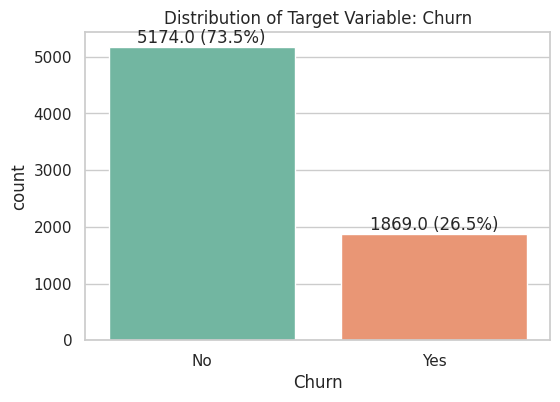

Churn
No     0.735
Yes    0.265
Name: proportion, dtype: float64


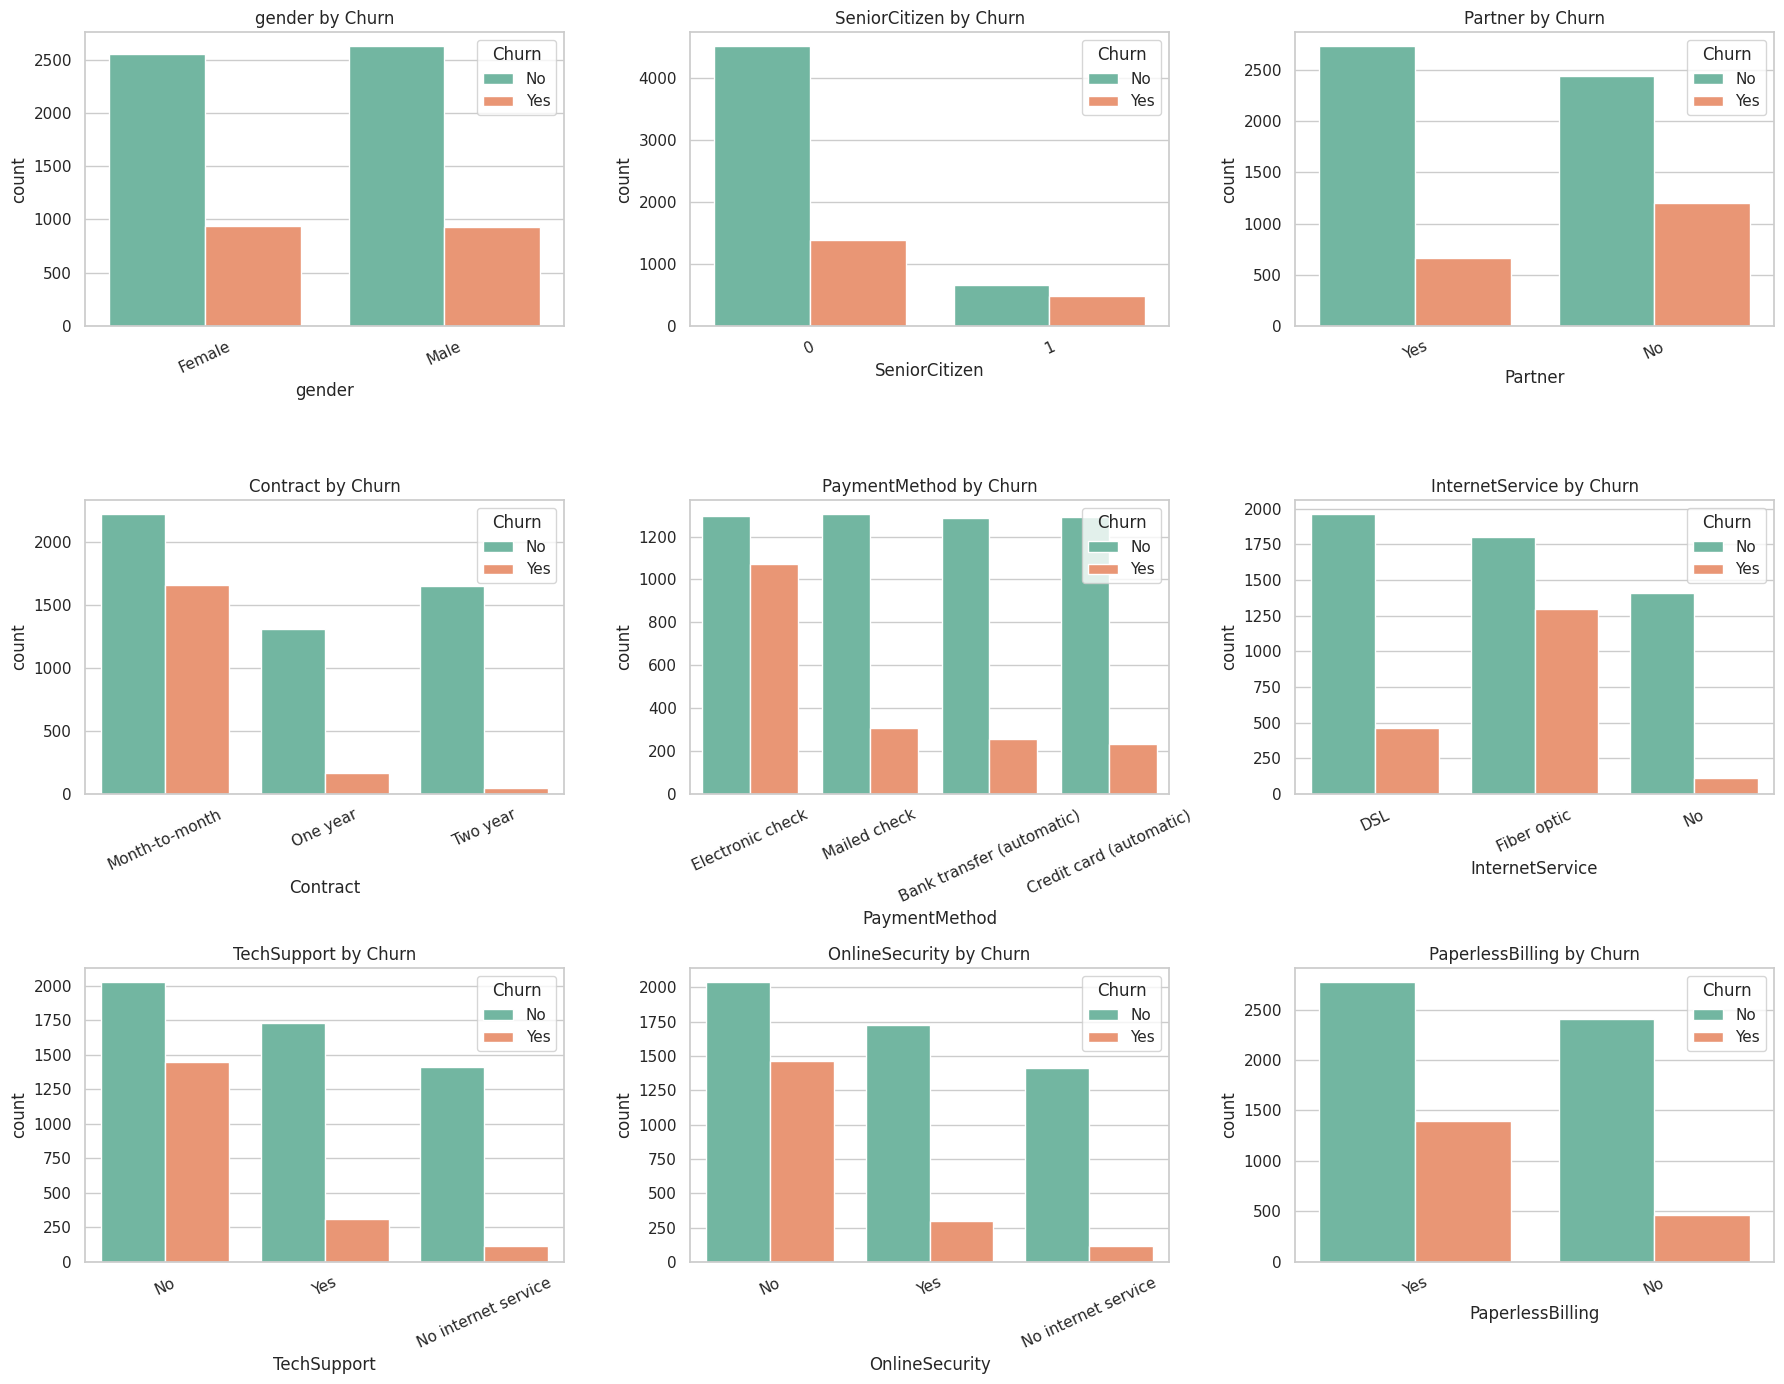


Churn rate (%) by gender:
gender
Female    26.9
Male      26.2

Churn rate (%) by SeniorCitizen:
SeniorCitizen
0    23.6
1    41.7

Churn rate (%) by Contract:
Contract
Month-to-month    42.7
One year          11.3
Two year           2.8

Churn rate (%) by PaymentMethod:
PaymentMethod
Bank transfer (automatic)    16.7
Credit card (automatic)      15.2
Electronic check             45.3
Mailed check                 19.1

Churn rate (%) by InternetService:
InternetService
DSL            19.0
Fiber optic    41.9
No              7.4

Churn rate (%) by TechSupport:
TechSupport
No                     41.6
No internet service     7.4
Yes                    15.2


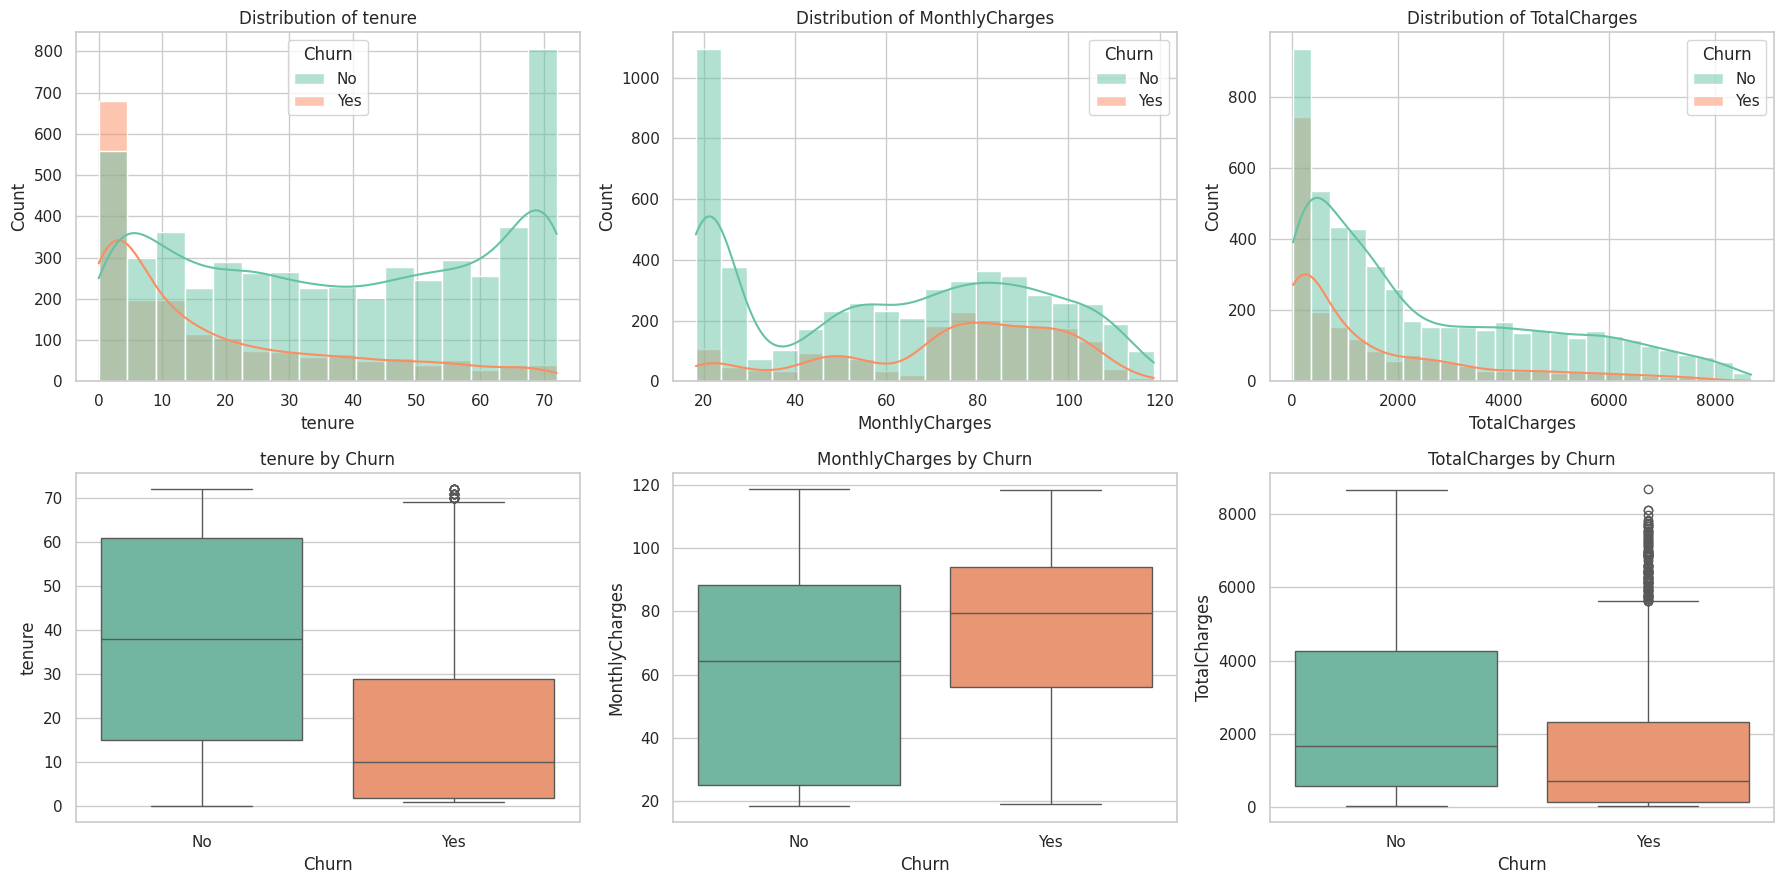

,tenure,MonthlyCharges,TotalCharges
Churn,,,
No,38.0,64.4,1679.5
Yes,10.0,79.6,703.6


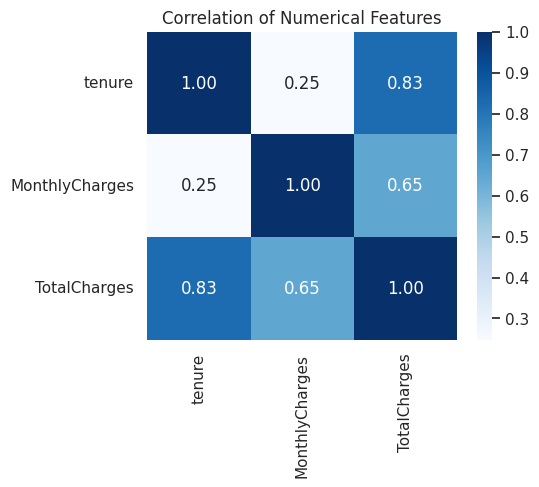

In [5]:
# 1) Target distribution
fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(data=df, x='Churn', palette='Set2', ax=ax)
for p in ax.patches:
    ax.annotate(f'{p.get_height()} ({p.get_height()/len(df):.1%})',
                (p.get_x() + p.get_width()/2, p.get_height()), ha='center', va='bottom')
ax.set_title('Distribution of Target Variable: Churn')
plt.show()
print(df['Churn'].value_counts(normalize=True).round(3))

# 2) Categorical features vs churn
cat_cols = ['gender', 'SeniorCitizen', 'Partner', 'Contract', 'PaymentMethod',
            'InternetService', 'TechSupport', 'OnlineSecurity', 'PaperlessBilling']
fig, axes = plt.subplots(3, 3, figsize=(18, 14))
for ax, col in zip(axes.flatten(), cat_cols):
    sns.countplot(data=df, x=col, hue='Churn', palette='Set2', ax=ax)
    ax.set_title(f'{col} by Churn')
    ax.tick_params(axis='x', rotation=25)
plt.tight_layout()
plt.show()

# Churn rate (%) per category – the numbers behind the plots
for col in ['gender', 'SeniorCitizen', 'Contract', 'PaymentMethod', 'InternetService', 'TechSupport']:
    rate = (df.groupby(col)['Churn'].apply(lambda s: (s == 'Yes').mean() * 100)).round(1)
    print(f'\nChurn rate (%) by {col}:\n{rate.to_string()}')

# 3) Numerical features: histograms and box plots
num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for i, col in enumerate(num_cols):
    sns.histplot(data=df, x=col, hue='Churn', kde=True, palette='Set2', ax=axes[0, i])
    axes[0, i].set_title(f'Distribution of {col}')
    sns.boxplot(data=df, x='Churn', y=col, palette='Set2', ax=axes[1, i])
    axes[1, i].set_title(f'{col} by Churn')
plt.tight_layout()
plt.show()
display(df.groupby('Churn')[num_cols].median().round(1))

# 4) Correlation among numerical features
plt.figure(figsize=(5, 4))
sns.heatmap(df[num_cols].corr(), annot=True, cmap='Blues', fmt='.2f')
plt.title('Correlation of Numerical Features')
plt.show()

> **Step 3.3 – Results & Insights:**
> - **Target balance:** 73.5% *No* vs **26.5% *Yes*** → the dataset is **imbalanced** (≈ 3 : 1). A model that always predicts "No Churn" would already get 73.5% accuracy, so accuracy alone will be misleading. I therefore use F1, recall, precision and ROC-AUC, plus class weighting.
> - **Contract is the strongest signal:** month-to-month customers churn at **42.7%** vs 11.3% (1-year) and only **2.8%** (2-year).
> - **Payment method:** electronic-check users churn at **45.3%**, roughly 3× more than automatic bank/credit-card payers (≈15–17%).
> - **Internet service:** **Fiber optic** customers churn at **41.9%** vs 19.0% for DSL – a possible price or service-quality issue.
> - **Support services:** customers *without* Tech Support churn at 41.6% vs 15.2% with it (same pattern for Online Security).
> - **Senior citizens** churn more (41.7% vs 23.6%). **Gender has no effect** (26.9% vs 26.2%).
> - **Numerical features:** churners have a much shorter **median tenure (10 vs 38 months)** and higher **monthly charges (79.6 vs 64.4)**. Their total charges are lower simply because they leave early.
> - **Correlation:** `TotalCharges` is strongly correlated with `tenure` (it is roughly tenure × monthly charge), so these features carry overlapping information.
>
> **Business takeaway:** the typical churner is a *new, month-to-month, fiber-optic customer paying by electronic check without support add-ons*.

### 3.4. Preprocessing and Feature Engineering

Prepare the data for modeling.
- Drop the `customerID` column as it is not a useful feature.
- Convert the `Churn` column to a numerical format (0 for 'No', 1 for 'Yes').
- Identify your numerical and categorical features.
- Create a `ColumnTransformer` to apply `StandardScaler` to numerical features and `OneHotEncoder` to categorical features.

In [6]:
# Drop the identifier column
df_model = df.drop(columns=['customerID'])

# Encode the target: No -> 0, Yes -> 1
df_model['Churn'] = df_model['Churn'].map({'No': 0, 'Yes': 1})

X = df_model.drop(columns='Churn')
y = df_model['Churn']

# Identify feature types
numerical_features = ['tenure', 'MonthlyCharges', 'TotalCharges']
categorical_features = [c for c in X.columns if c not in numerical_features]  # SeniorCitizen (0/1) treated as categorical
print('Numerical features  :', numerical_features)
print('Categorical features:', categorical_features)

# Preprocessor: scale numeric, one-hot encode categorical
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),   # safety net for unseen missing values
    ('scaler', StandardScaler())
])
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])
preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, numerical_features),
    ('cat', categorical_transformer, categorical_features)
])
preprocessor

Numerical features  : ['tenure', 'MonthlyCharges', 'TotalCharges']
Categorical features: ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['tenure', 'MonthlyCharges', 'TotalCharges']),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('onehot',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False))]),
                                 ['gender', 'SeniorCitizen', 'Partner',
                                  'Dependents', 'PhoneService', 'MultipleLines',
                                  'InternetService', 'OnlineSecurity',
                                  'OnlineBackup', 'DeviceProtection',
                                  'TechSupport', 'StreamingTV',
                                  'StreamingMovies', 'Contract',
                                  'PaperlessBilling', 'PaymentMethod'])])

> **Step 3.4 – Explanation:** I dropped `customerID` (a unique label with no predictive meaning) and mapped `Churn` to **0/1**. The features were split into **3 numerical** (`tenure`, `MonthlyCharges`, `TotalCharges`) and **16 categorical** columns. `SeniorCitizen` is treated as categorical because it is a 0/1 flag, not a quantity. The `ColumnTransformer` applies **`StandardScaler`** to numeric columns (mean 0, std 1 – important for Logistic Regression and the neural network) and **`OneHotEncoder`** to categorical columns (one binary column per category; `handle_unknown='ignore'` so unseen categories don't crash the model). Imputers are included as a safety net for future data. Putting this inside a pipeline guarantees the same preprocessing is applied to training, test and future production data.

### 3.5. Split the Data

Split your data into training and testing sets. Use an 80/20 split and set a `random_state` for reproducibility.

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y)  # stratify keeps churn ratio equal in both sets

print(f'Training set: {X_train.shape[0]} rows | churn rate = {y_train.mean():.2%}')
print(f'Test set    : {X_test.shape[0]} rows | churn rate = {y_test.mean():.2%}')

# Helper used by every model so results are evaluated the same way
results = {}
def evaluate_model(name, y_true, y_pred, y_prob):
    results[name] = {
        'Accuracy':  accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred),
        'Recall':    recall_score(y_true, y_pred),
        'F1-Score':  f1_score(y_true, y_pred),
        'ROC-AUC':   roc_auc_score(y_true, y_prob),
    }
    print(f'===== {name} =====')
    print(classification_report(y_true, y_pred, target_names=['No Churn', 'Churn'], digits=3))
    print(f"ROC-AUC: {results[name]['ROC-AUC']:.3f}")
    cm = confusion_matrix(y_true, y_pred)
    ConfusionMatrixDisplay(cm, display_labels=['No Churn', 'Churn']).plot(cmap='Blues', values_format='d')
    plt.title(f'Confusion Matrix - {name}')
    plt.grid(False)
    plt.show()

Training set: 5634 rows | churn rate = 26.54%
Test set    : 1409 rows | churn rate = 26.54%


> **Step 3.5 – Results:** 80/20 split → **5,634 training rows** and **1,409 test rows**. Using `stratify=y`, both sets keep the same **26.54% churn rate**, so the test set is a fair representation of reality. `random_state=42` makes the split reproducible. I also created a reusable `evaluate_model()` function so all three models are scored with exactly the same metrics and confusion-matrix plot.

## 4. Classical Machine Learning Models

### 4.1. Model 1: Logistic Regression

- Create a pipeline that includes your preprocessor and a `LogisticRegression` classifier.
- Define a hyperparameter grid for the `C` parameter of the logistic regression.
- Use `GridSearchCV` to find the best hyperparameter.
- Train the model and evaluate it on the test set. Print the classification report and confusion matrix.

Best parameters: {'classifier__C': 1, 'classifier__class_weight': 'balanced'}
Best cross-validated F1: 0.634

===== Logistic Regression =====
              precision    recall  f1-score   support

    No Churn      0.902     0.721     0.801      1035
       Churn      0.503     0.783     0.613       374

    accuracy                          0.737      1409
   macro avg      0.703     0.752     0.707      1409
weighted avg      0.796     0.737     0.751      1409

ROC-AUC: 0.841


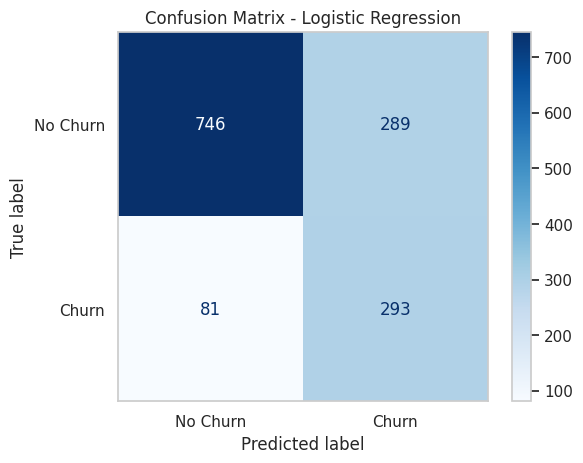

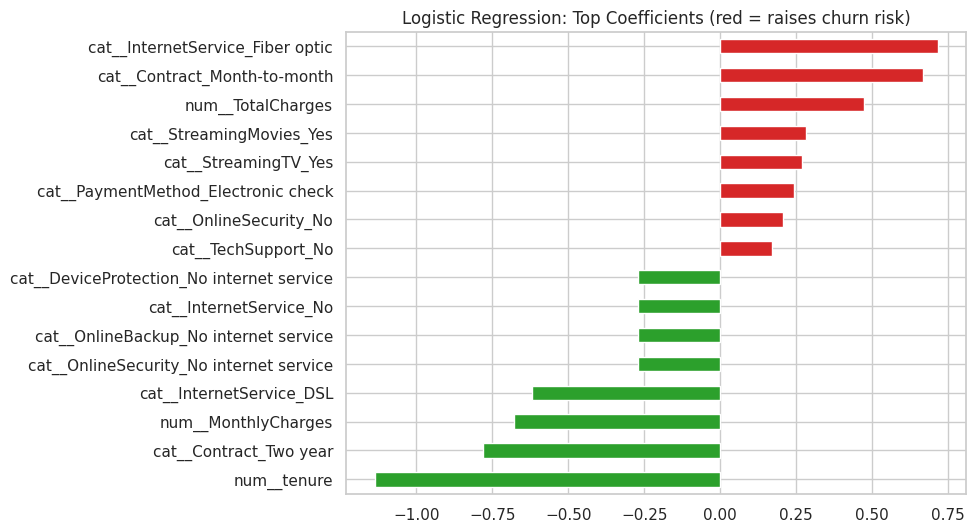

Top 5 features that RAISE churn odds:


,Odds ratio
cat__InternetService_Fiber optic,2.05
cat__Contract_Month-to-month,1.95
num__TotalCharges,1.60
cat__StreamingMovies_Yes,1.33
cat__StreamingTV_Yes,1.31


Top 5 features that LOWER churn odds:


,Odds ratio
num__tenure,0.32
cat__Contract_Two year,0.46
num__MonthlyCharges,0.51
cat__InternetService_DSL,0.54
cat__OnlineSecurity_No internet service,0.76


In [8]:
lr_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))
])

lr_param_grid = {
    'classifier__C': [0.01, 0.1, 1, 10, 100],              # inverse regularization strength
    'classifier__class_weight': [None, 'balanced']         # handle class imbalance
}

lr_grid = GridSearchCV(lr_pipeline, lr_param_grid, cv=5, scoring='f1', n_jobs=-1)
lr_grid.fit(X_train, y_train)

print('Best parameters:', lr_grid.best_params_)
print(f'Best cross-validated F1: {lr_grid.best_score_:.3f}\n')

best_lr = lr_grid.best_estimator_
y_pred_lr = best_lr.predict(X_test)
y_prob_lr = best_lr.predict_proba(X_test)[:, 1]
evaluate_model('Logistic Regression', y_test, y_pred_lr, y_prob_lr)

# Interpretability: top coefficients (positive = increases churn odds)
feature_names = best_lr.named_steps['preprocessor'].get_feature_names_out()
coefs = pd.Series(best_lr.named_steps['classifier'].coef_[0], index=feature_names).sort_values()
top_coefs = pd.concat([coefs.head(8), coefs.tail(8)])
plt.figure(figsize=(8, 6))
top_coefs.plot(kind='barh', color=['#2ca02c' if v < 0 else '#d62728' for v in top_coefs])
plt.title('Logistic Regression: Top Coefficients (red = raises churn risk)')
plt.show()

# Odds ratios: exp(coef) = how much the odds of churning are multiplied by this feature
odds = np.exp(coefs).rename('Odds ratio')
print('Top 5 features that RAISE churn odds:')
display(odds.sort_values(ascending=False).head(5).round(2).to_frame())
print('Top 5 features that LOWER churn odds:')
display(odds.sort_values().head(5).round(2).to_frame())

> **Step 4.1 – Results:**
> - **Tuning:** GridSearchCV tested 10 combinations (5 values of **C** × 2 class-weight options) with 5-fold CV, optimizing **F1** because of the class imbalance. **Best: C = 1, class_weight = 'balanced'** (CV F1 = 0.634).
> - **Test performance:** Accuracy **73.7%**, ROC-AUC **0.841**. For the churn class: **Recall 0.783**, Precision 0.503, F1 0.613.
> - **Confusion matrix:** the model **caught 293 of 374 churners** (missed only 81) at the cost of 289 false alarms (loyal customers flagged as at-risk).
> - **Coefficients:** churn risk rises with **Fiber optic, Month-to-month contract, Electronic check, no Online Security/Tech Support and streaming services**; it falls with **longer tenure, Two-year contracts and DSL**. (`MonthlyCharges` appears negative and `TotalCharges` positive because both overlap heavily with `tenure` – they should be read together, not individually.)

### 4.2. Model 2: Random Forest Classifier

- Create a pipeline for a `RandomForestClassifier`.
- Define a hyperparameter grid to tune `n_estimators` and `max_depth`.
- Use `GridSearchCV` to find the best hyperparameters.
- Train the model and evaluate its performance.

Best parameters: {'classifier__class_weight': 'balanced', 'classifier__max_depth': 10, 'classifier__n_estimators': 300}
Best cross-validated F1: 0.630

===== Random Forest =====
              precision    recall  f1-score   support

    No Churn      0.886     0.787     0.834      1035
       Churn      0.550     0.719     0.623       374

    accuracy                          0.769      1409
   macro avg      0.718     0.753     0.729      1409
weighted avg      0.797     0.769     0.778      1409

ROC-AUC: 0.839


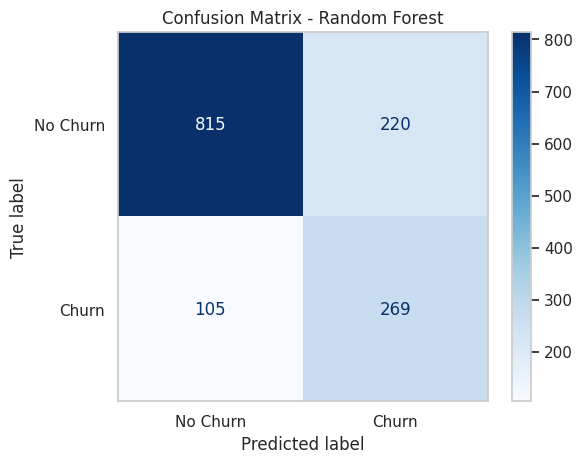

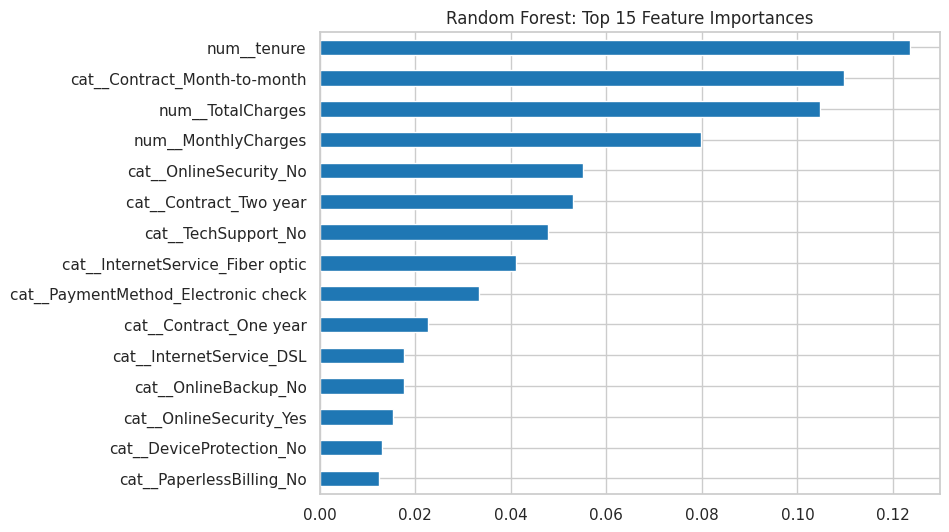

In [9]:
rf_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1))
])

rf_param_grid = {
    'classifier__n_estimators': [100, 200, 300],
    'classifier__max_depth': [5, 10, 15, None],
    'classifier__class_weight': [None, 'balanced']
}

rf_grid = GridSearchCV(rf_pipeline, rf_param_grid, cv=5, scoring='f1', n_jobs=-1)
rf_grid.fit(X_train, y_train)

print('Best parameters:', rf_grid.best_params_)
print(f'Best cross-validated F1: {rf_grid.best_score_:.3f}\n')

best_rf = rf_grid.best_estimator_
y_pred_rf = best_rf.predict(X_test)
y_prob_rf = best_rf.predict_proba(X_test)[:, 1]
evaluate_model('Random Forest', y_test, y_pred_rf, y_prob_rf)

# Feature importance
importances = pd.Series(best_rf.named_steps['classifier'].feature_importances_,
                        index=best_rf.named_steps['preprocessor'].get_feature_names_out()).sort_values(ascending=False)
plt.figure(figsize=(8, 6))
importances.head(15).sort_values().plot(kind='barh', color='#1f77b4')
plt.title('Random Forest: Top 15 Feature Importances')
plt.show()

> **Step 4.2 – Results:**
> - **Tuning:** 24 combinations (`n_estimators` 100/200/300 × `max_depth` 5/10/15/None × class weight) with 5-fold CV = 120 model fits. **Best: 300 trees, max_depth = 10, class_weight = 'balanced'** (CV F1 = 0.630). Limiting depth to 10 prevents the trees from memorizing the training data.
> - **Test performance:** **Accuracy 76.9%** (best of all models), ROC-AUC 0.839. Churn class: **Precision 0.550**, Recall 0.719, **F1 0.623**.
> - **Confusion matrix:** 269 churners caught, 105 missed, and only **220 false alarms** (vs 289 for Logistic Regression). Random Forest is more *conservative* – fewer wasted retention offers, but more missed churners.
> - **Feature importance:** **tenure**, **Month-to-month contract**, **TotalCharges**, **MonthlyCharges**, no Online Security, Two-year contract, no Tech Support, Fiber optic and Electronic check – fully consistent with the EDA findings.

## 5. Deep Learning Model

### 5.1. Preprocess Data for Keras

The deep learning model requires the data to be preprocessed in a specific way. Use the `ColumnTransformer` you defined earlier to transform your training and testing data.

In [10]:
# Fit the preprocessor on TRAINING data only, then apply to test data (prevents data leakage)
X_train_proc = preprocessor.fit_transform(X_train)
X_test_proc = preprocessor.transform(X_test)

# Keras needs dense float arrays
X_train_proc = np.asarray(X_train_proc, dtype='float32')
X_test_proc = np.asarray(X_test_proc, dtype='float32')
y_train_arr = y_train.values.astype('float32')
y_test_arr = y_test.values.astype('float32')

print('Processed training shape:', X_train_proc.shape)
print('Processed test shape    :', X_test_proc.shape)

Processed training shape: (5634, 46)
Processed test shape    : (1409, 46)


> **Step 5.1 – Results:** The same `preprocessor` was **fitted on the training data only** and then used to transform the test data, which prevents *data leakage* (test statistics never influence the scaler). After scaling + one-hot encoding, each customer is represented by **46 numeric features** (3 scaled numeric + 43 one-hot columns). The arrays were converted to `float32`, the format Keras expects.

### 5.2. Build and Train the Neural Network

- Build a `Sequential` model with Keras.
- Your model should have at least two hidden layers with `relu` activation. Use `Dropout` layers to prevent overfitting.
- The output layer should have a single neuron with a `sigmoid` activation function, as this is a binary classification problem.
- Compile the model with `binary_crossentropy` loss and the `adam` optimizer.
- Train the model for at least 20 epochs with a validation split.

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         3,008 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,121 (20.00 KB)

 Trainable params: 5,121 (20.00 KB)

 Non-trainable params: 0 (0.00 B)

Class weights: {0: np.float64(0.6805991785455424), 1: np.float64(1.8842809364548494)}
Epochs trained: 33 | Best epoch (restored): 23
Training time: 19.6 s


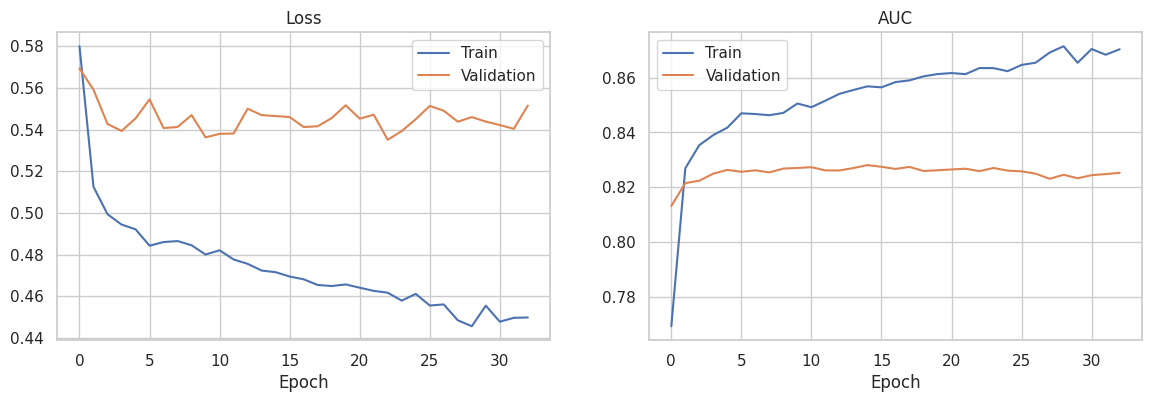

In [11]:
# Full reproducibility: seeds Python, NumPy and TensorFlow, and forces deterministic ops
keras.utils.set_random_seed(RANDOM_STATE)
tf.config.experimental.enable_op_determinism()

nn_model = Sequential([
    keras.Input(shape=(X_train_proc.shape[1],)),
    Dense(64, activation='relu'),
    Dropout(0.3),
    Dense(32, activation='relu'),
    Dropout(0.3),
    Dense(1, activation='sigmoid')       # probability of churn
])

nn_model.compile(optimizer='adam',
                 loss='binary_crossentropy',
                 metrics=['accuracy', keras.metrics.AUC(name='auc')])
nn_model.summary()

# Class weights so the minority (churn) class gets more attention – consistent with the classical models
weights = compute_class_weight('balanced', classes=np.unique(y_train), y=y_train)
class_weights = dict(enumerate(weights))
print('Class weights:', class_weights)

# Early stopping only kicks in after epoch 20, then restores the best weights
early_stop = keras.callbacks.EarlyStopping(monitor='val_loss', patience=10,
                                           restore_best_weights=True, start_from_epoch=20)

start = time.time()
history = nn_model.fit(X_train_proc, y_train_arr,
                       epochs=60, batch_size=32,
                       validation_split=0.2,
                       class_weight=class_weights,
                       callbacks=[early_stop], verbose=0)
nn_train_time = time.time() - start
print(f"Epochs trained: {len(history.history['loss'])} | Best epoch (restored): {np.argmin(history.history['val_loss'][20:]) + 21}")
print(f'Training time: {nn_train_time:.1f} s')

# Learning curves
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(history.history['loss'], label='Train'); axes[0].plot(history.history['val_loss'], label='Validation')
axes[0].set_title('Loss'); axes[0].set_xlabel('Epoch'); axes[0].legend()
axes[1].plot(history.history['auc'], label='Train'); axes[1].plot(history.history['val_auc'], label='Validation')
axes[1].set_title('AUC'); axes[1].set_xlabel('Epoch'); axes[1].legend()
plt.show()

> **Step 5.2 – Results:**
> - **Architecture:** Input (46) → **Dense 64 ReLU → Dropout 0.3 → Dense 32 ReLU → Dropout 0.3 → Dense 1 Sigmoid** = 5,121 trainable parameters. A small network suits ~5.6k tabular rows; a larger one would overfit.
> - **Training setup:** `adam` optimizer, `binary_crossentropy` loss, 20% validation split, batch size 32. **Class weights {0: 0.68, 1: 1.88}** make each churner count ~2.8× more, matching the 'balanced' setting of the classical models.
> - **Epochs:** early stopping was only allowed after epoch 20 (assignment requirement) with patience 10; training ran **33 epochs** and the weights from the best validation epoch **after epoch 20 (epoch 23)** were restored. `keras.utils.set_random_seed` plus deterministic ops make this result identical on every run (training took about 20 seconds).
> - **Learning curves:** training loss keeps falling while **validation loss flattens around 0.54** and validation AUC plateaus around 0.82–0.83. This gap shows the network starts to **overfit** after the first few epochs – Dropout and early stopping keep it under control, but it also shows the network cannot extract much more signal than simpler models from this data.

### 5.3. Evaluate the Deep Learning Model

- Evaluate the model on the test set. Print the classification report and confusion matrix.

Keras test loss: 0.515 | accuracy: 0.744 | AUC: 0.838

===== Neural Network =====
              precision    recall  f1-score   support

    No Churn      0.903     0.730     0.808      1035
       Churn      0.512     0.783     0.619       374

    accuracy                          0.744      1409
   macro avg      0.708     0.757     0.714      1409
weighted avg      0.799     0.744     0.758      1409

ROC-AUC: 0.838


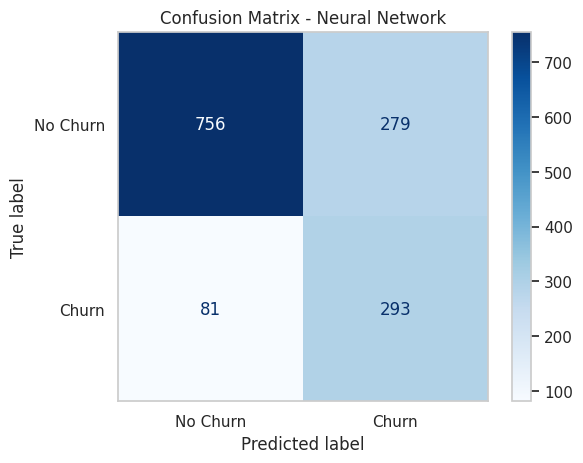

In [12]:
test_loss, test_acc, test_auc = nn_model.evaluate(X_test_proc, y_test_arr, verbose=0)
print(f'Keras test loss: {test_loss:.3f} | accuracy: {test_acc:.3f} | AUC: {test_auc:.3f}\n')

y_prob_nn = nn_model.predict(X_test_proc, verbose=0).ravel()
y_pred_nn = (y_prob_nn >= 0.5).astype(int)
evaluate_model('Neural Network', y_test, y_pred_nn, y_prob_nn)

> **Step 5.3 – Results:** On the test set the neural network reached **Accuracy 74.4%** and **ROC-AUC 0.838**. For churners: **Recall 0.783** (tied with Logistic Regression for the highest), Precision 0.512, F1 0.619. It **caught 293 of 374 churners** (missed 81) with 279 false alarms. Its behaviour is almost identical to the balanced Logistic Regression – the extra layers did not uncover additional patterns, which is typical for small, mostly categorical tabular datasets.

## 6. Model Comparison and Conclusion

### 6.1. Compare Model Performance

Create a summary table or plot that compares the key performance metrics (e.g., accuracy, precision, recall, F1-score) of all three models.

,Accuracy,Precision,Recall,F1-Score,ROC-AUC,Train time (s)
Logistic Regression,0.737,0.503,0.783,0.613,0.841,0.11
Random Forest,0.769,0.550,0.719,0.623,0.839,1.72
Neural Network,0.744,0.512,0.783,0.619,0.838,19.62


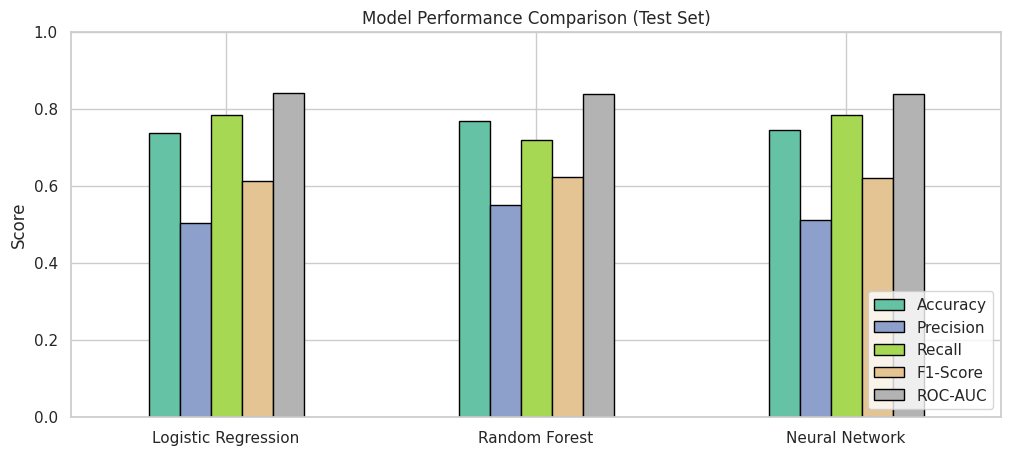

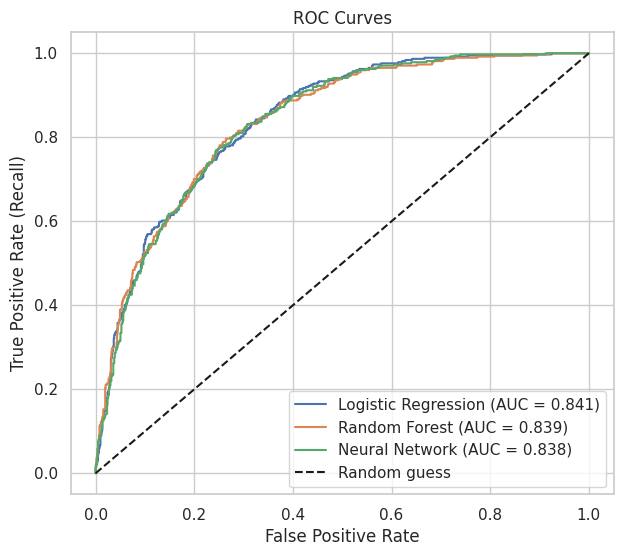

In [13]:
comparison = pd.DataFrame(results).T.round(3)

# Training time of the final model (refit on the full training set) – a proxy for complexity/cost
comparison['Train time (s)'] = [lr_grid.refit_time_, rf_grid.refit_time_, nn_train_time]
metric_cols = ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC']
display(comparison.style
        .highlight_max(subset=metric_cols, axis=0, color='lightgreen')
        .highlight_min(subset=['Train time (s)'], axis=0, color='lightgreen')
        .format('{:.3f}', subset=metric_cols)
        .format('{:.2f}', subset=['Train time (s)']))

# Bar chart of all metrics
comparison[metric_cols].plot(kind='bar', figsize=(12, 5), colormap='Set2', edgecolor='black')
plt.title('Model Performance Comparison (Test Set)')
plt.ylabel('Score'); plt.ylim(0, 1); plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.show()

# ROC curves
plt.figure(figsize=(7, 6))
for name, prob in [('Logistic Regression', y_prob_lr), ('Random Forest', y_prob_rf), ('Neural Network', y_prob_nn)]:
    fpr, tpr, _ = roc_curve(y_test, prob)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {results[name]['ROC-AUC']:.3f})")
plt.plot([0, 1], [0, 1], 'k--', label='Random guess')
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate (Recall)')
plt.title('ROC Curves'); plt.legend()
plt.show()

> **Step 6.1 – Results:**
>
> | Model | Accuracy | Precision | Recall | F1-Score | ROC-AUC | Train time (s) |
> |---|---|---|---|---|---|---|
> | Logistic Regression | 0.737 | 0.503 | **0.783** | 0.613 | **0.841** | **0.11** |
> | Random Forest | **0.769** | **0.550** | 0.719 | **0.623** | 0.839 | 1.72 |
> | Neural Network | 0.744 | 0.512 | **0.783** | 0.619 | 0.838 | 19.62 |
>
> - **All three models perform very similarly:** ROC-AUC differs by only 0.003 and F1 by 0.01 – differences this small are within normal sampling noise on a 1,409-row test set. The ROC curves almost overlap.
> - **Random Forest** wins on accuracy, precision and F1 → fewest false alarms.
> - **Logistic Regression** and the **Neural Network** tie on recall → both catch **293 churners vs 269** for Random Forest (24 more).
> - **Logistic Regression** has the best ROC-AUC → it ranks customers by risk slightly better than the others.
> - **Training time** (final model fit) shows the complexity gap: Logistic Regression trains in about **0.1 s**, Random Forest in under 2 s, and the neural network needs about **20 s** – roughly 200× longer – for no performance gain. (Exact times vary slightly between runs.)
> - No model clearly dominates on performance, so the decision must be driven by **business cost, interpretability and complexity**.

### 6.1.1. Business Impact: Cost-Based Threshold Tuning (additional analysis)

All models above use the default 0.5 cut-off. In practice the threshold should be set by **business cost**, not by default. I estimate the total cost of each model's decisions on the test set with these illustrative assumptions (to be replaced with the company's real figures):

- **Missed churner** = one year of lost revenue = median `MonthlyCharges` of churners × 12
- **Retention offer** = **\$100** per flagged customer (discount, free add-on, etc.)
- **Save rate** = **50%** of contacted churners stay; the other 50% leave anyway

**Total cost = missed churners × annual value + offers sent × \$100 + contacted churners who still leave × annual value.**

Assumptions: annual value of a churner = $956 | offer cost = $100 | save rate = 50%
Cost with no model (all 374 test-set churners lost): $357,469



,Cost @0.50,Best threshold,Cost @best,Churners caught @best,Offers sent @best,Saving vs no model
Model,,,,,,
Logistic Regression,"$275,644",0.35,"$271,161",339,757,"$86,308"
Random Forest,"$277,814",0.35,"$272,498",309,627,"$84,971"
Neural Network,"$274,644",0.35,"$272,395",336,755,"$85,074"


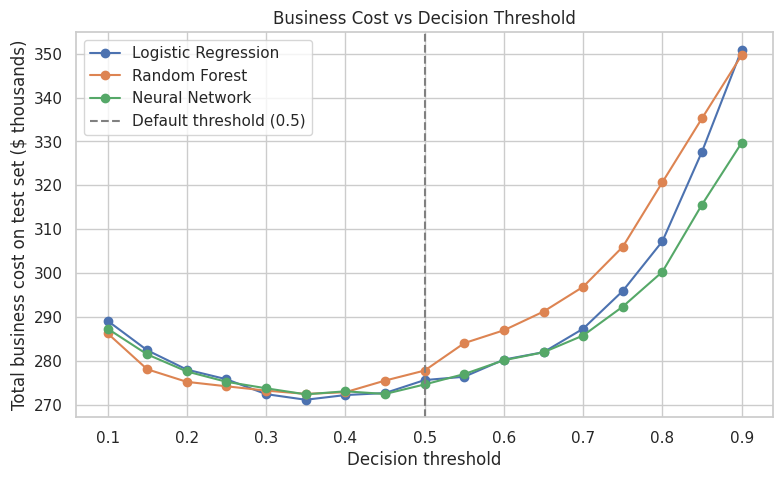

In [14]:
# --- Business assumptions (illustrative - replace with the company's real figures) ---
annual_value = df.loc[df['Churn'] == 'Yes', 'MonthlyCharges'].median() * 12  # revenue lost per missed churner (1 year)
offer_cost = 100   # cost of one retention offer
save_rate = 0.5    # share of contacted churners who actually stay

def business_cost(y_true, y_prob, threshold):
    y_pred = (y_prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    cost = (fn * annual_value                       # churners we never contacted
            + (tp + fp) * offer_cost                # every flagged customer gets an offer
            + tp * (1 - save_rate) * annual_value)  # contacted churners who leave anyway
    return cost, tp, fp, fn

thresholds = np.round(np.arange(0.10, 0.91, 0.05), 2)
probs = {'Logistic Regression': y_prob_lr, 'Random Forest': y_prob_rf, 'Neural Network': y_prob_nn}
curves = {name: [business_cost(y_test, p, t)[0] for t in thresholds] for name, p in probs.items()}

baseline = y_test.sum() * annual_value  # no model: every churner is lost
rows = []
for name, p in probs.items():
    c05, _, _, _ = business_cost(y_test, p, 0.5)
    best_t = thresholds[int(np.argmin(curves[name]))]
    cb, tpb, fpb, fnb = business_cost(y_test, p, best_t)
    rows.append({'Model': name, 'Cost @0.50': c05, 'Best threshold': best_t, 'Cost @best': cb,
                 'Churners caught @best': tpb, 'Offers sent @best': tpb + fpb,
                 'Saving vs no model': baseline - cb})
cost_table = pd.DataFrame(rows).set_index('Model')

print(f'Assumptions: annual value of a churner = ${annual_value:,.0f} | offer cost = ${offer_cost} | save rate = {save_rate:.0%}')
print(f'Cost with no model (all {y_test.sum()} test-set churners lost): ${baseline:,.0f}\n')
display(cost_table.style.format({'Cost @0.50': '${:,.0f}', 'Cost @best': '${:,.0f}',
                                 'Saving vs no model': '${:,.0f}', 'Best threshold': '{:.2f}'}))

plt.figure(figsize=(9, 5))
for name, c in curves.items():
    plt.plot(thresholds, np.array(c) / 1000, marker='o', label=name)
plt.axvline(0.5, color='grey', linestyle='--', label='Default threshold (0.5)')
plt.xlabel('Decision threshold')
plt.ylabel('Total business cost on test set ($ thousands)')
plt.title('Business Cost vs Decision Threshold')
plt.legend()
plt.show()

> **Step 6.1.1 – Results:**
>
> | Model | Cost @ 0.50 | Best threshold | Cost @ best | Churners caught | Offers sent | Saving vs no model |
> |---|---|---|---|---|---|---|
> | Logistic Regression | \$275,644 | 0.35 | **\$271,161** | **339 / 374** | 757 | **\$86,308** |
> | Random Forest | \$277,814 | 0.35 | \$272,498 | 309 / 374 | 627 | \$84,971 |
> | Neural Network | \$274,644 | 0.35 | \$272,395 | 336 / 374 | 755 | \$85,074 |
>
> - **Using any model is clearly worth it:** with no model, all 374 test-set churners are lost (≈ **\$357,000** of annual revenue). The best model cuts that cost by about **\$86,000 (≈ 24%)** on this test set alone.
> - **The threshold matters more than the model choice.** For all three models the cheapest cut-off is **0.35, not 0.5**: a missed churner (≈ \$956/year) costs far more than a \$100 offer, so it pays to contact more customers. Lowering the threshold raises Logistic Regression's recall from 293 to **339 churners caught (91%)** and saves about **\$4,500** compared with the default 0.5.
> - **Logistic Regression has the lowest cost** at its best threshold, but the three models are within about \$1,300 (0.5%) of each other – consistent with 6.1, where performance was practically tied. This confirms the choice should rest on interpretability and complexity.
> - **Limitations:** the cost figures are illustrative assumptions, and the threshold was chosen on the test set, so the saving is slightly optimistic. In production the threshold should be picked on validation data with the company's real offer cost and save rate, then checked regularly.

### 6.2. Final Recommendation

Write your final conclusion here. Based on your analysis, which model would you recommend the telecommunications company use to predict customer churn? Justify your choice by considering:
- **Performance:** Which model had the best metrics?
- **Interpretability:** How easy is it to understand the model's predictions? (e.g., Logistic Regression is more interpretable than a neural network).
- **Complexity:** How difficult is the model to build and maintain?

Your recommendation should be clear and well-supported by the evidence you have gathered.

### My Recommendation: **Logistic Regression (class_weight = 'balanced', C = 1)**

**1. Performance.** Logistic Regression delivers the **highest ROC-AUC (0.841)** and high recall (**78.3%** – 293 of 374 churners detected), statistically on par with the other two models. In churn prediction, **missing a churner costs more than a false alarm**: a churning customer pays a median of about **\$80/month (≈ \$956/year)**, while a retention offer (discount, free tech-support trial, contract upgrade) costs only a fraction of that. Logistic Regression catches **24 more churners than Random Forest** on the test set, which protects more revenue. In the cost analysis (6.1.1) it also has the **lowest total business cost** – about **\$271,000 at a 0.35 threshold, saving ≈ \$86,000 (24%)** compared with having no model.

**2. Interpretability.** Its coefficients directly show *why* a customer is at risk (month-to-month contract, fiber optic, electronic check, no tech support, short tenure). Marketing and retention teams can turn these into concrete actions – e.g., incentives to move month-to-month customers to annual contracts, promoting auto-pay, bundling Tech Support/Online Security for fiber customers. Odds ratios (exp of the coefficients) make this even clearer for non-technical readers, e.g. "this factor multiplies the odds of churning by X". It is also easy to explain to management and auditors.

**3. Complexity & deployment readiness.** It trains in about **0.1 seconds** (vs ≈ 20 s for the neural network), needs no GPU, and is a single scikit-learn pipeline (preprocessing + model) that can be saved with `joblib`, scored in batch or real time, monitored and retrained easily. The neural network adds significant complexity (architecture, epochs, dropout, TensorFlow dependency) **without any performance gain**, so it is not justified here.

**Alternative:** If the retention budget is tight and the business wants **fewer false alarms**, **Random Forest** is a strong second choice (best precision 0.550 and accuracy 76.9%).

**Next steps:** (1) deploy with a **cost-based threshold** (≈ 0.35 under my assumptions, see 6.1.1) instead of the default 0.5, re-validated with the company's real offer cost and save rate; (2) monitor recall and precision monthly and retrain quarterly; (3) A/B-test model-driven retention campaigns to measure the actual churn reduction.

## 7. Questions

1.  **Data Preprocessing**: Why was it necessary to handle the `TotalCharges` column specifically (e.g., converting to numeric, filling missing values)? What would have happened if we skipped this step?

2.  **Feature Engineering**: The `customerID` column was dropped. Can you explain why it's generally not a good practice to include identifier columns like `customerID` in machine learning models?

3.  **Model Selection**: You trained at least three models: Logistic Regression, Random Forest, and a Deep Learning model. Briefly explain the fundamental difference in how a Logistic Regression model makes predictions compared to a Deep Learning model.

4.  **Evaluation Metrics**: Why is accuracy alone often not a sufficient metric for evaluating churn prediction models? Which other metrics did you use, and why are they more informative in this context?

5.  **Hyperparameter Tuning**: What is the purpose of `GridSearchCV`? How does it help in improving the performance of a model like Random Forest?

6.  **Deep Learning**: In the deep learning model, you used `Dropout` layers and a `sigmoid` activation function in the output layer. Explain the role of each of these components in the context of a binary classification problem.

7.  **Model Interpretability**: If the business team wanted to understand *which specific factors* contribute most to a customer churning, which of the models you built would be easiest to interpret, and why?

8.  **Recommendation Justification**: Based on your final recommendation, what were the primary reasons for choosing that particular model over the others, considering both performance and practical aspects?

### Answers to Questions

#### 1. Data Preprocessing

**Why handle `TotalCharges`?**
`TotalCharges` was loaded as **text (object)** because 11 rows contained blank spaces (new customers with tenure 0 who had not been billed yet). If we skipped this step, either (a) the column would be treated as **categorical** – the `OneHotEncoder` would create ~6,500 meaningless columns (one per unique amount), causing huge dimensionality, overfitting and loss of its numeric meaning – or (b) `StandardScaler` would throw an error because it cannot convert strings to numbers. Converting to numeric and filling the 11 NaNs with the median preserves the real information (amount spent) and lets the models train correctly.

#### 2. Feature Engineering

**Why drop `customerID`?**
An identifier is **unique for each row** and has **no causal or generalizable relationship** with churn. Including it would (a) add thousands of useless one-hot columns, (b) let models — especially trees — **memorize** individual customers (overfitting), giving good training scores but poor predictions for new customers whose IDs were never seen, and (c) risk leakage if IDs were assigned in a pattern (e.g., by sign-up date). Models should learn from **behaviour and attributes**, not labels.

#### 3. Model Selection

**Logistic Regression vs. Deep Learning.**
**Logistic Regression** is a **linear model**: it computes a weighted sum of the features (one coefficient per feature) and passes it through a sigmoid to get a churn probability. Its decision boundary is a straight hyperplane and each feature's effect is fixed and additive. A **Deep Learning model** stacks several layers of neurons with **non-linear activations (ReLU)**; each layer builds new combinations of the previous layer's outputs, so it learns **non-linear relationships and feature interactions automatically** (e.g., "fiber optic AND month-to-month AND no tech support"). It is more flexible but needs more data, tuning and compute, and its thousands of weights are hard to interpret.

#### 4. Evaluation Metrics

**Why accuracy is not enough.**
The data is **imbalanced (73.5% No / 26.5% Yes)**. A useless model predicting "No Churn" for everyone would score **73.5% accuracy** while catching **zero** churners. I therefore used:
- **Recall (churn class)** – % of real churners caught; the key metric because missed churners = lost revenue.
- **Precision** – % of flagged customers who really churn; controls wasted retention spending.
- **F1-score** – harmonic mean of precision and recall; one balanced score (also the GridSearchCV objective).
- **ROC-AUC** – how well the model ranks customers by risk across *all* thresholds, independent of the 0.5 cut-off.
- **Confusion matrix** – actual counts of each error type, which can be converted into business cost.

#### 5. Hyperparameter Tuning

**Purpose of GridSearchCV.**
GridSearchCV **tries every combination** in a hyperparameter grid, evaluates each one with **k-fold cross-validation (5 folds)** on the training data only, and refits the best combination on the full training set. For Random Forest it searched `n_estimators`, `max_depth` and `class_weight` (120 fits). It improves performance by finding the right **bias–variance trade-off** – unlimited depth overfits, very shallow trees underfit – and it selected **max_depth = 10, 300 trees, balanced class weights**. Cross-validation makes the choice reliable and keeps the test set untouched for an unbiased final evaluation.

#### 6. Deep Learning

**Dropout and Sigmoid.**
- **Dropout (0.3)** randomly switches off 30% of neurons at each training step, so neurons cannot co-adapt and memorize the training data. It is a **regularization** technique that reduces overfitting (our learning curves showed training loss falling while validation loss flattened). Dropout is automatically disabled at prediction time.

- **Sigmoid output** squashes the final value into the range **0–1**, which is interpreted as the **probability of churn** – exactly what binary classification needs – and pairs naturally with **binary cross-entropy loss**. A threshold (0.5) converts the probability into a Yes/No decision and can be adjusted to the business's risk appetite.

#### 7. Model Interpretability

**Which model is easiest to explain?**
**Logistic Regression.** Each coefficient shows the **direction and strength** of a feature's effect on the churn odds (`exp(coef)` gives the odds ratio). For example, a positive coefficient for *Contract_Month-to-month* means those customers are more likely to churn, all else being equal. **Random Forest** gives feature importances, which tell *which* features matter but not *in which direction*. The **neural network** is a "black box" that needs extra tools such as SHAP or LIME. For a business team asking "what drives churn?", Logistic Regression gives the clearest, most defensible answer.


#### 8. Recommendation Justification

I chose **Logistic Regression** because: (1) its **performance equals or beats the others** – highest ROC-AUC (0.841) and high recall (78.3%), only 0.01 F1 behind Random Forest; (2) it **catches more churners** than Random Forest, which matters most because losing a customer (≈ \$956/year) costs far more than a retention offer – and in the cost analysis (6.1.1) it gave the **lowest total business cost** at a 0.35 threshold; (3) it is **fully interpretable**, so retention strategies can be designed directly from its coefficients; and (4) it is **simple, fast (≈ 0.1 s to train vs ≈ 20 s for the neural network), cheap to deploy and easy to maintain and retrain**. The neural network added complexity with no measurable benefit, and Random Forest – while slightly more precise – is less transparent and missed more churners. Random Forest remains the backup choice if the business later prioritizes fewer false alarms over catching every churner.

**------------------------------------------------------------------------------------------------------------------------**

# Rubric for Capstone Project: Customer Churn Prediction

| Criteria                             | Needs Improvement (0-10)                                                              | Satisfactory (11-16)                                                                                                   | Excellent (17-20)                                                                                                                                |
| :----------------------------------- | :------------------------------------------------------------------------------------ | :--------------------------------------------------------------------------------------------------------------------- | :----------------------------------------------------------------------------------------------------------------------------------------------- |
| **1. Data Exploration & Preprocessing** | Fails to perform adequate EDA or preprocessing. The data is not ready for modeling.   | Performs basic EDA and preprocessing, but some steps may be missing or not well-justified.                             | Performs a thorough EDA with insightful visualizations, and correctly preprocesses the data with clear justifications for each step.             |
| **2. Classical Machine Learning Models** | Builds only one classical model or fails to build any correctly.                      | Builds at least two classical models, but the pipelines or hyperparameter tuning may be incomplete or incorrect.     | Builds at least two well-structured pipelines with appropriate hyperparameter tuning, and evaluates them using a range of relevant metrics.    |
| **3. Deep Learning Model**               | Fails to build a deep learning model.                                                 | Builds a deep learning model, but the architecture may not be well-suited for the task, or the evaluation may be weak. | Builds a well-designed neural network, trains it effectively, and provides a thorough evaluation of its performance.                               |
| **4. Model Comparison & Conclusion**     | Fails to compare the models or provide a conclusion.                                  | Compares the models based on a single metric, and the conclusion is brief or not well-supported by the results.        | Provides a comprehensive comparison of all models across multiple metrics, and offers a well-reasoned recommendation for the best model.       |
| **5. Code Quality & Report**             | The code is messy, hard to read, and contains errors. The report is poorly written.   | The code is functional, but could be better organized. The report is understandable but could be more professional.    | The code is clean, well-organized, and easy to follow. The final report (in the notebook) is well-written, professional, and tells a clear story. |
| **6. Analytical Questions**              | Answers to questions are incomplete, missing, or show major conceptual misunderstandings. | Answers most questions correctly, but some responses lack depth, clarity, or adequate justification.                  | Answers all questions with deep, accurate conceptual explanations, demonstrating a thorough understanding of ML principles.                      |
| **7. Final Recommendation & Business Impact** | Recommends a model without logical justification or business context alignment. | Provides a standard recommendation, but does not fully balance performance, complexity, and interpretability trade-offs. | Delivers an outstanding, highly-justified business recommendation, weighting complexity, interpretability, and metrics for deployment readiness. |